In [2]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
from datetime import datetime, timedelta
import os
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.lines import Line2D

/tmp/user/28413/ipykernel_919567/4076755245.py:5: FutureWarning: In a future version, xarray will not decode the variable 'time' into a timedelta64 dtype based on the presence of a timedelta-like 'units' attribute by default. Instead it will rely on the presence of a timedelta64 'dtype' attribute, which is now xarray's default way of encoding timedelta64 values.
To continue decoding into a timedelta64 dtype, either set `decode_timedelta=True` when opening this dataset, or add the attribute `dtype='timedelta64[ns]'` to this variable on disk.
To opt-in to future behavior, set `decode_timedelta=False`.
  ds = xr.open_zarr(path) if path.endswith(".zarr") else xr.open_dataset(path)
/tmp/user/28413/ipykernel_919567/4076755245.py:5: FutureWarning: In a future version, xarray will not decode the variable 'time' into a timedelta64 dtype based on the presence of a timedelta-like 'units' attribute by default. Instead it will rely on the presence of a timedelta64 'dtype' attribute, which is now xa

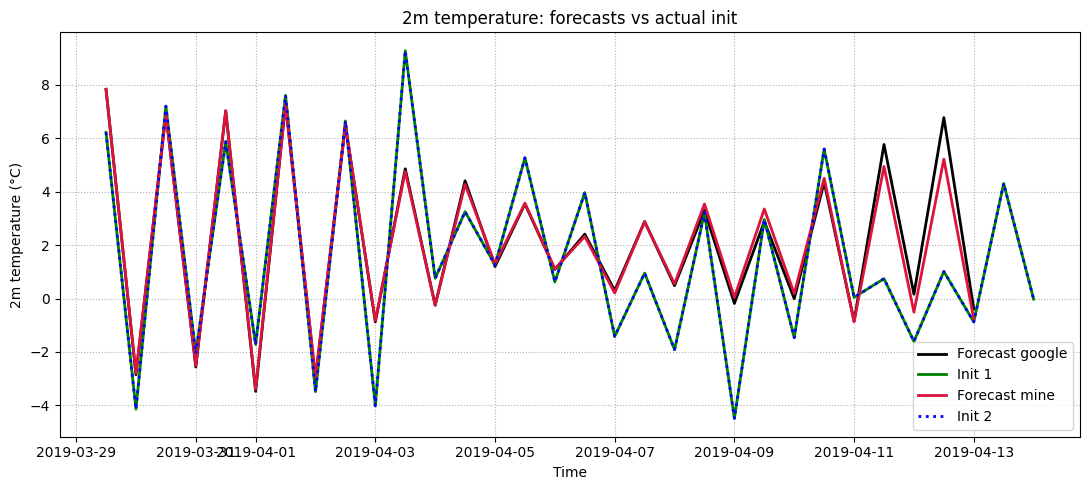

In [ ]:
lat, lon = 50.23, -121.58
zvar, nvar = "2m_temperature", "t2m"

def load(path, var, base=None, shift_hours=0):
    ds = xr.open_zarr(path) if path.endswith(".zarr") else xr.open_dataset(path)
    if "batch" in ds.dims: ds = ds.squeeze("batch", drop=True)
    ds = ds.rename({k:v for k,v in {"lat":"latitude","lon":"longitude","sample":"number"}.items() if k in ds.dims or k in ds.coords})
    da = ds[var].mean("number") if "number" in ds[var].dims else ds[var]
    if float(da.mean()) > 100: da = da - 273.15
    if base is not None and not np.issubdtype(da.time.dtype, np.datetime64):
        t0 = pd.Timestamp(base) + pd.Timedelta(hours=shift_hours)
        off = pd.to_timedelta(da.time.values) if np.issubdtype(da.time.dtype, np.timedelta64) else pd.to_timedelta(da.time.values, unit="h")
        da = da.assign_coords(time=t0 + off)
    return da.sel(latitude=lat, longitude=(lon % 360 if float(da.longitude.max()) > 180 else lon), method="nearest")

base = pd.Timestamp("2019-03-29 00:00")  # set this to the real zarr start datetime

z1 = load("predictions/Google_init_2019-03-29T00_30d_8ens_predictions.zarr", "2m_temperature", base=base)
z2 = load("predictions/init_2019-03-29T00_30d_8ens_predictions.zarr", "2m_temperature", base=base)

n1 = load("Google_dataset_source-era5_date-2019-03-29_res-1.0_levels-13_steps-30.nc", "2m_temperature", base=base, shift_hours=12)
n2 = load("init_files/init_2019-03-29T00_30d.nc", "2m_temperature", base=base, shift_hours=12)
plt.figure(figsize=(11, 5))
plt.plot(z1.time, z1, color="black", lw=2, label="Forecast google")
plt.plot(n1.time, n1, color="green", ls="-", lw=2, label="Init 1")
plt.plot(z2.time, z2, color="crimson", lw=2, label="Forecast mine")
plt.plot(n2.time, n2, color="blue", ls=":", lw=2, label="Init 2")
plt.xlabel("Time"); plt.ylabel("2m temperature (°C)")
plt.title("2m temperature: forecasts vs actual init")
plt.grid(True, ls=":"); plt.legend(); plt.tight_layout(); plt.show()

In [4]:
# Helpers for datetime plots
def standardize(ds):
    return ds.rename({k: v for k, v in {"lat": "latitude", "lon": "longitude", "sample": "number"}.items()
                      if k in ds.coords or k in ds.dims})

def to_celsius(da):
    return da - 273.15 if float(da.mean()) > 100 else da

def anchor_time(ds, init_time):
    return ds.assign_coords(time=pd.to_datetime(init_time) + ds["time"])

def city_series(da, lat, lon, lon360=False):
    lon = lon % 360 if lon360 else lon
    return da.sel(latitude=lat, longitude=lon, method="nearest")

2021-06-25T12:00:00.000000000 2021-07-06T00:00:00.000000000


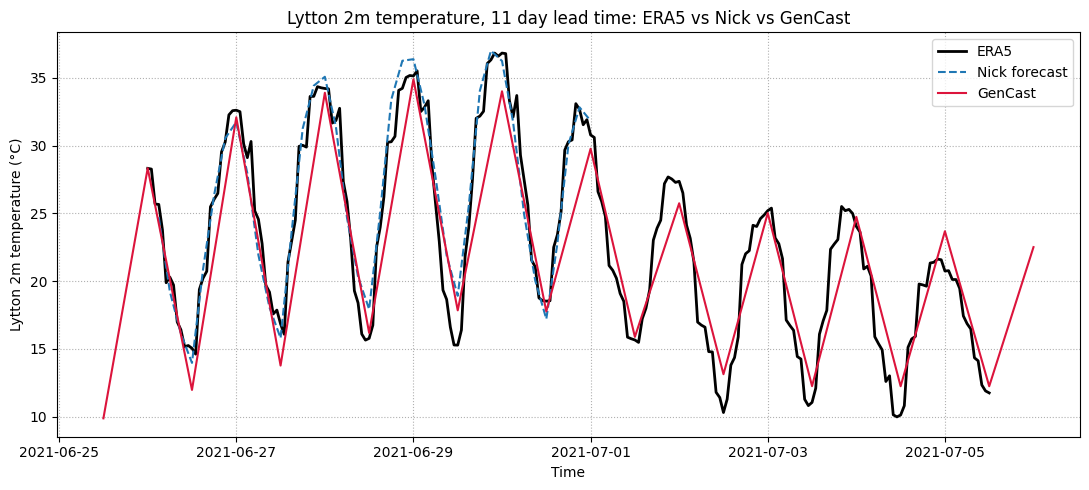

In [9]:
# plotting Lytton, BC, Canada as an example
Date = "2021-06-26"
Date2 = str(pd.to_datetime(datetime.strptime(Date, "%Y-%m-%d") - timedelta(days=1)).date())
era5 = xr.open_dataset("/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/era5/pnw025/sfc/2021.nc", engine="netcdf4")
nick = xr.open_dataset("/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_"+Date+".nc", engine="netcdf4")
gencast = xr.open_zarr("/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/init_"+Date+"T00_10d_18ens_0seed_predictions.zarr")

if "batch" in gencast.dims:
    gencast = gencast.squeeze("batch")

# --- Standardize ---
era5, nick, gencast = map(standardize, (era5, nick, gencast))

# --- Variable selection ---
era5_da = to_celsius(era5["t2m"].sel(time=slice(Date+"T00:00:00", "2021-07-05T12:00:00")))
nick_da = to_celsius(nick["t2m"])
gencast_da = anchor_time(to_celsius(gencast["2m_temperature"]), datetime.strptime(Date, "%Y-%m-%d"))

nick_da.loc[dict(time=nick_da.time[0])] = np.nan

# --- Location ---
city, city_lat, city_lon = "Lytton", 50.224444, -121.581944

era5_city = city_series(era5_da, city_lat, city_lon)
nick_city = city_series(nick_da, city_lat, city_lon).mean("number")
gencast_city = city_series(gencast_da, city_lat, city_lon, lon360=True).mean("number")

# --- Align times ---
start = max(map(pd.to_datetime, [era5_city.time.values[0], nick_city.time.values[0], gencast_city.time.values[0]]))
#end = min(map(pd.to_datetime, [era5_city.time.values[-1], nick_city.time.values[-1], gencast_city.time.values[-1]]))
end = pd.to_datetime(era5_city.time.values[-1])

era5_city = era5_city.sel(time=slice(start, end))
#nick_city = nick_city.sel(time=slice(start, end))
print(gencast_city.time.values[0], gencast_city.time.values[-1])
#gencast_city = gencast_city.sel(time=slice(start, end))

# --- Plot ---
plt.figure(figsize=(11, 5))
plt.plot(era5_city.time, era5_city, label="ERA5", color="black", linewidth=2)
plt.plot(nick_city.time, nick_city, label="Nick forecast", linestyle="--")
plt.plot(gencast_city.time, gencast_city, label="GenCast", color="crimson")
plt.xlabel("Time")
plt.ylabel(f"{city} 2m temperature (°C)")
plt.title(f"{city} 2m temperature, 11 day lead time: ERA5 vs Nick vs GenCast")
plt.grid(True, linestyle=":")
plt.legend()
plt.tight_layout()
plt.show()

2021-06-25T12:00:00.000000000 2021-07-06T00:00:00.000000000


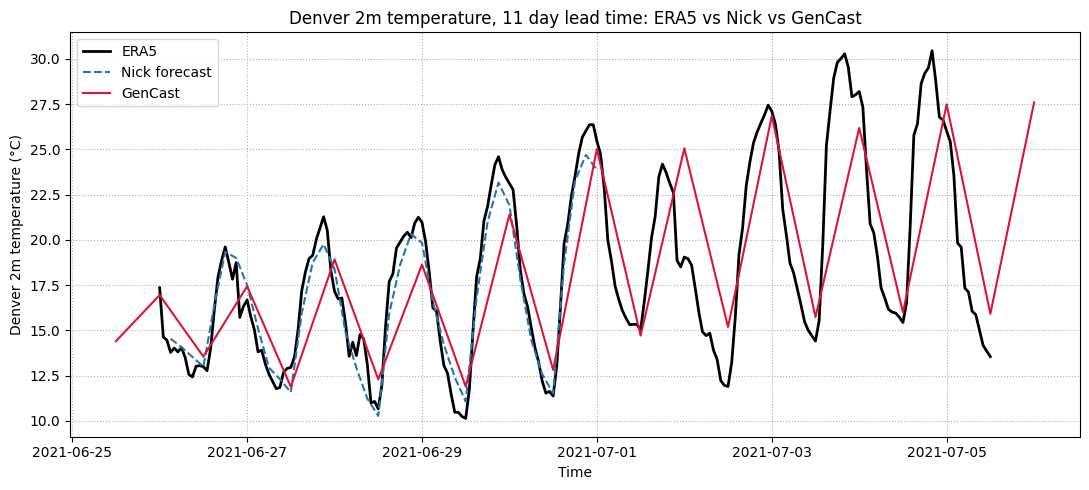

In [17]:
# plotting New York, US as an example
Date = "2021-06-26"
Date2 = str(pd.to_datetime(datetime.strptime(Date, "%Y-%m-%d") - timedelta(days=1)).date())
era5 = xr.open_dataset("/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/era5/pnw025/sfc/2021.nc", engine="netcdf4")
nick = xr.open_dataset("/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_"+Date+".nc", engine="netcdf4")
gencast = xr.open_zarr("/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/init_"+Date+"T00_10d_18ens_0seed_predictions.zarr")

if "batch" in gencast.dims:
    gencast = gencast.squeeze("batch")

# --- Standardize ---
era5, nick, gencast = map(standardize, (era5, nick, gencast))

# --- Variable selection ---
era5_da = to_celsius(era5["t2m"].sel(time=slice(Date+"T00:00:00", "2021-07-05T12:00:00")))
nick_da = to_celsius(nick["t2m"])
gencast_da = anchor_time(to_celsius(gencast["2m_temperature"]), datetime.strptime(Date, "%Y-%m-%d"))

nick_da.loc[dict(time=nick_da.time[0])] = np.nan

# --- Location ---
city, city_lat, city_lon = "Denver", 39.7392, -104.9903

era5_city = city_series(era5_da, city_lat, city_lon)
nick_city = city_series(nick_da, city_lat, city_lon).mean("number")
gencast_city = city_series(gencast_da, city_lat, city_lon, lon360=True).mean("number")

# --- Align times ---
start = max(map(pd.to_datetime, [era5_city.time.values[0], nick_city.time.values[0], gencast_city.time.values[0]]))
#end = min(map(pd.to_datetime, [era5_city.time.values[-1], nick_city.time.values[-1], gencast_city.time.values[-1]]))
end = pd.to_datetime(era5_city.time.values[-1])

era5_city = era5_city.sel(time=slice(start, end))
#nick_city = nick_city.sel(time=slice(start, end))
print(gencast_city.time.values[0], gencast_city.time.values[-1])
#gencast_city = gencast_city.sel(time=slice(start, end))

# --- Plot ---
plt.figure(figsize=(11, 5))
plt.plot(era5_city.time, era5_city, label="ERA5", color="black", linewidth=2)
plt.plot(nick_city.time, nick_city, label="Nick forecast", linestyle="--")
plt.plot(gencast_city.time, gencast_city, label="GenCast", color="crimson")
plt.xlabel("Time")
plt.ylabel(f"{city} 2m temperature (°C)")
plt.title(f"{city} 2m temperature, 11 day lead time: ERA5 vs Nick vs GenCast")
plt.grid(True, linestyle=":")
plt.legend()
plt.tight_layout()
plt.show()

In [16]:
for name, ds in [("ERA5", era5), ("Nick", nick), ("GenCast", gencast)]:
    print(f"\n{name}")
    print("lat:", float(ds.latitude.min()), "to", float(ds.latitude.max()))
    print("lon:", float(ds.longitude.min()), "to", float(ds.longitude.max()))

    if "time" in ds.coords:
        print("time:", ds.time.values[0], "to", ds.time.values[-1])


ERA5
lat: 30.0 to 70.0
lon: -150.0 to -100.0
time: 2021-06-01T00:00:00.000000000 to 2021-08-31T23:00:00.000000000

Nick
lat: 30.0 to 70.0
lon: -150.0 to -100.0
time: 2021-06-26T00:00:00.000000000 to 2021-07-01T00:00:00.000000000

GenCast
lat: -90.0 to 90.0
lon: 0.0 to 359.0
time: -43200000000000 nanoseconds to 864000000000000 nanoseconds


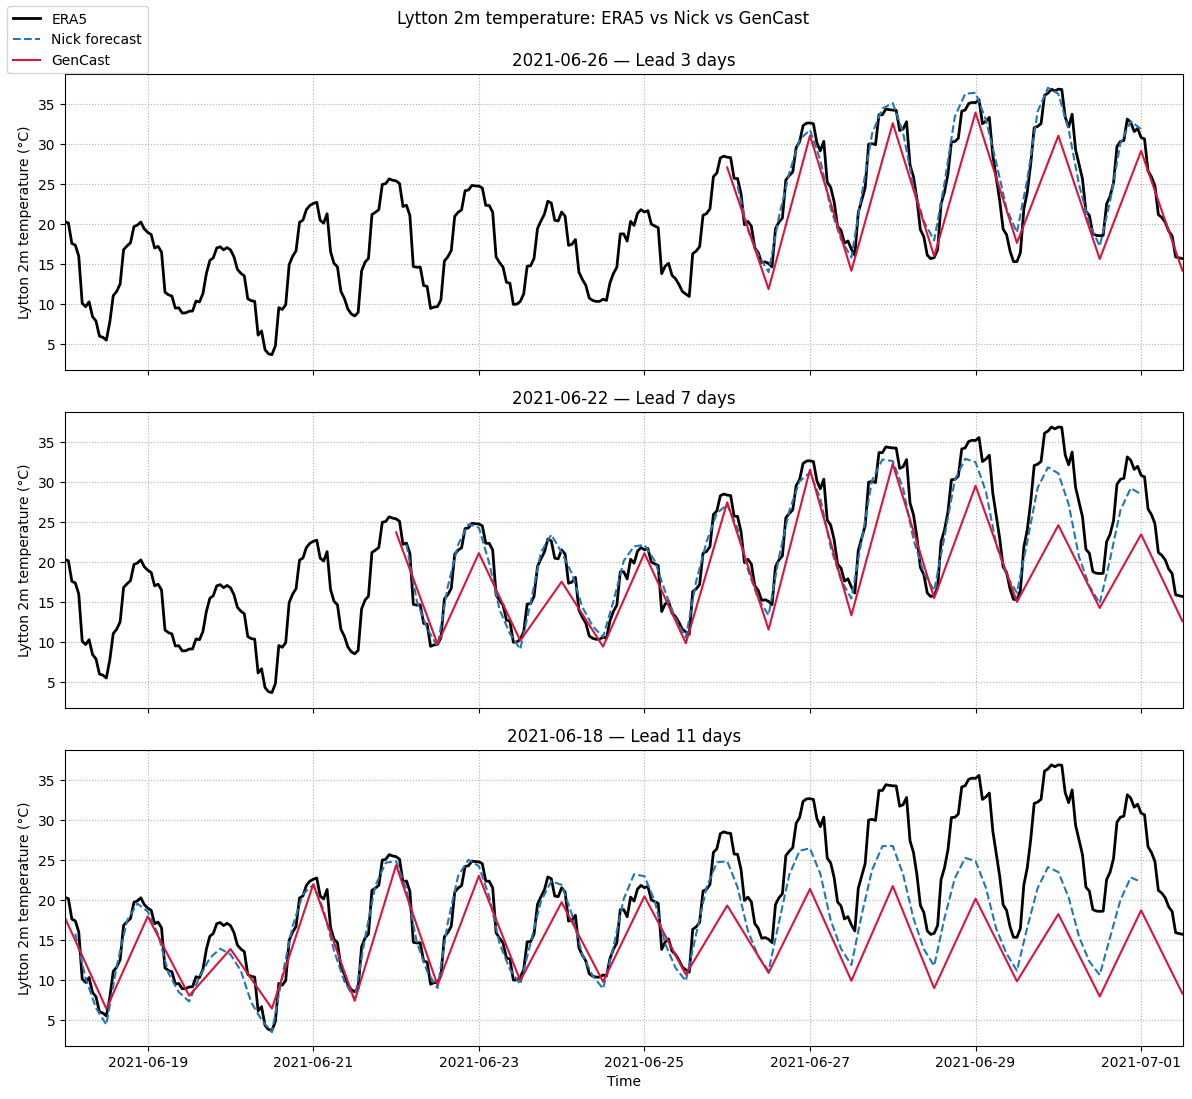

In [ ]:
 
era5 = standardize(xr.open_dataset(
    "/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/era5/pnw025/sfc/2021.nc",
    engine="netcdf4"
))

city, city_lat, city_lon = "Lytton", 50.224444, -121.581944
cases = [
    ("2021-06-26", "Lead 3 days"),
    ("2021-06-22", "Lead 7 days"),
    ("2021-06-18", "Lead 11 days"),
]

x_start = pd.Timestamp("2021-06-18 00:00:00")
x_end   = pd.Timestamp("2021-07-01 12:00:00")

fig, axes = plt.subplots(3, 1, figsize=(12, 11), sharex=True, sharey=True)

for ax, (Date, lead_label) in zip(axes, cases):
    Date2 = str((pd.to_datetime(Date) - timedelta(days=1)).date())

    nick = standardize(xr.open_dataset(
        f"/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_{Date}.nc",
        engine="netcdf4"
    ))
    gencast = standardize(xr.open_zarr(f"predictions/init_{Date2}T00_30d_8ens_predictions.zarr"))
    if "batch" in gencast.dims:
        gencast = gencast.squeeze("batch")

    era5_da = to_celsius(era5["t2m"].sel(time=slice(x_start, x_end)))
    nick_da = to_celsius(nick["t2m"])
    gencast_da = anchor_time(to_celsius(gencast["2m_temperature"]),
                             datetime.strptime(Date2, "%Y-%m-%d") + timedelta(hours=12))

    nick_da.loc[dict(time=nick_da.time[0])] = np.nan

    era5_city = city_series(era5_da, city_lat, city_lon)
    nick_city = city_series(nick_da, city_lat, city_lon).mean("number")
    gencast_city = city_series(gencast_da, city_lat, city_lon, lon360=True).mean("number")

    ax.plot(era5_city.time, era5_city, color="black", linewidth=2)
    ax.plot(nick_city.time, nick_city, linestyle="--")
    ax.plot(gencast_city.time, gencast_city, color="crimson")

    ax.set_title(f"{Date} — {lead_label}")
    ax.set_ylabel(f"{city} 2m temperature (°C)")
    ax.set_xlim(x_start, x_end)
    ax.grid(True, linestyle=":")

legend_lines = [
    Line2D([0], [0], color="black", lw=2, label="ERA5"),
    Line2D([0], [0], ls="--", label="Nick forecast"),
    Line2D([0], [0], color="crimson", label="GenCast"),
]

fig.legend(handles=legend_lines, loc="upper left", ncol=1)

axes[-1].set_xlabel("Time")
fig.suptitle(f"{city} 2m temperature: ERA5 vs Nick vs GenCast", y=0.995)
fig.tight_layout()
plt.show()

/tmp/user/28413/ipykernel_3352894/4196048719.py:10: FutureWarning: In a future version, xarray will not decode the variable 'time' into a timedelta64 dtype based on the presence of a timedelta-like 'units' attribute by default. Instead it will rely on the presence of a timedelta64 'dtype' attribute, which is now xarray's default way of encoding timedelta64 values.
To continue decoding into a timedelta64 dtype, either set `decode_timedelta=True` when opening this dataset, or add the attribute `dtype='timedelta64[ns]'` to this variable on disk.
To opt-in to future behavior, set `decode_timedelta=False`.
  clim = xr.open_dataset(CLIM_FILE, chunks="auto")


('time', 'lat', 'lon') (30, 181, 360)
('lat', 'lon') (181, 360)


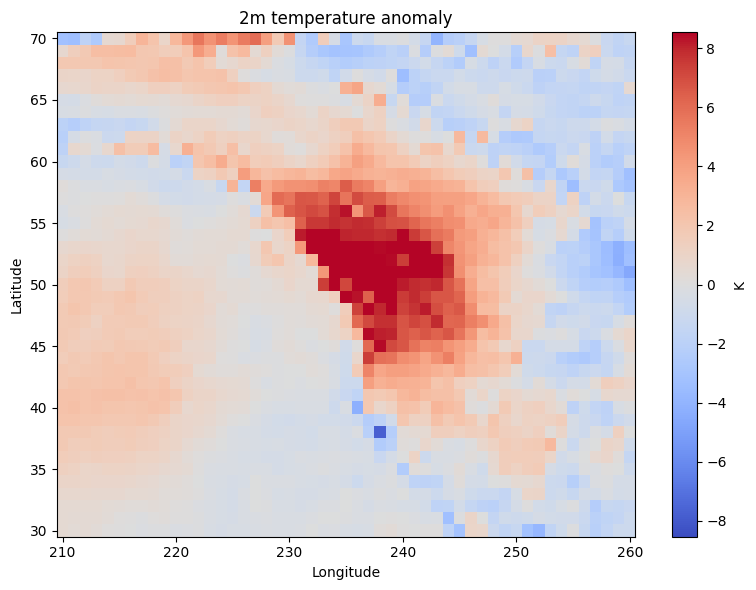

In [ ]:
# first go at anomaly maps vs climatology over 1959 to 2020
PRED_FILE = "predictions/init_2021-06-21T00_30d_8ens_predictions.zarr"
CLIM_FILE = "era5_june_climatology_1959_2020_2m_temperature.nc"
OUT_PNG = "anomaly_map_45N_52N_119W_123W.png"

LAT1, LAT2 = 30, 70
LON1, LON2 = -150, -100
TIDX = 0

pred = xr.open_zarr(PRED_FILE, consolidated=True, chunks="auto")
clim = xr.open_dataset(CLIM_FILE, chunks="auto")

pv = "2m_temperature" if "2m_temperature" in pred else "temperature"
cv = "2m_temperature_june_max_climatology" if "2m_temperature_june_max_climatology" in clim else list(clim.data_vars)[0]

if float(pred.lon.min()) < 0: pred = pred.assign_coords(lon=(pred.lon % 360)).sortby("lon")
if float(clim.lon.min()) < 0: clim = clim.assign_coords(lon=(clim.lon % 360)).sortby("lon")

lon1, lon2 = (LON1 % 360), (LON2 % 360)
lat_slice = slice(LAT1, LAT2) if pred.lat[0] < pred.lat[-1] else slice(LAT2, LAT1)

p = pred[pv]
for d in ["ens", "ensemble", "member", "batch", "sample"]:
    if d in p.dims:
        p = p.mean(d)   # or .max(d) if you want the warmest ensemble member

pmax = p.max("time")

print(p.dims, p.shape)
print(pmax.dims, pmax.shape)

for d in list(p.dims):
    if d == "time" and "time" in p.dims:
        p = p.isel(time=TIDX, drop=True)
    elif d not in ("lat", "lon"):
        p = p.mean(d)



c = clim[cv].squeeze(drop=True)
for d in list(c.dims):
    if d not in ("lat", "lon"):
        c = c.isel({d: 0}, drop=True)

p = p.sel(lat=lat_slice, lon=slice(lon1, lon2))
pmax = pmax.sel(lat=lat_slice, lon=slice(lon1, lon2))
c = c.sel(lat=lat_slice, lon=slice(lon1, lon2)).interp(lat=p.lat, lon=p.lon)

a = (pmax - c).squeeze(drop=True)
if a.ndim != 2:
    raise ValueError(f"Expected 2D field, got dims={a.dims}, shape={a.shape}")

v = np.nanpercentile(np.abs(a), 98)

fig, ax = plt.subplots(figsize=(8, 6))
m = ax.pcolormesh(a.lon.values, a.lat.values, a.values, shading="auto", cmap="coolwarm", vmin=-v, vmax=v)
ax.set_title("2m temperature anomaly")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
fig.colorbar(m, ax=ax, label="K")
plt.tight_layout()
plt.show()

/tmp/user/28413/ipykernel_3382867/399975862.py:16: FutureWarning: In a future version, xarray will not decode the variable 'time' into a timedelta64 dtype based on the presence of a timedelta-like 'units' attribute by default. Instead it will rely on the presence of a timedelta64 'dtype' attribute, which is now xarray's default way of encoding timedelta64 values.
To continue decoding into a timedelta64 dtype, either set `decode_timedelta=True` when opening this dataset, or add the attribute `dtype='timedelta64[ns]'` to this variable on disk.
To opt-in to future behavior, set `decode_timedelta=False`.
  clim = xr.open_dataset(CLIM_FILE, chunks="auto")
/tmp/user/28413/ipykernel_3382867/399975862.py:16: FutureWarning: In a future version, xarray will not decode the variable 'time' into a timedelta64 dtype based on the presence of a timedelta-like 'units' attribute by default. Instead it will rely on the presence of a timedelta64 'dtype' attribute, which is now xarray's default way of enco

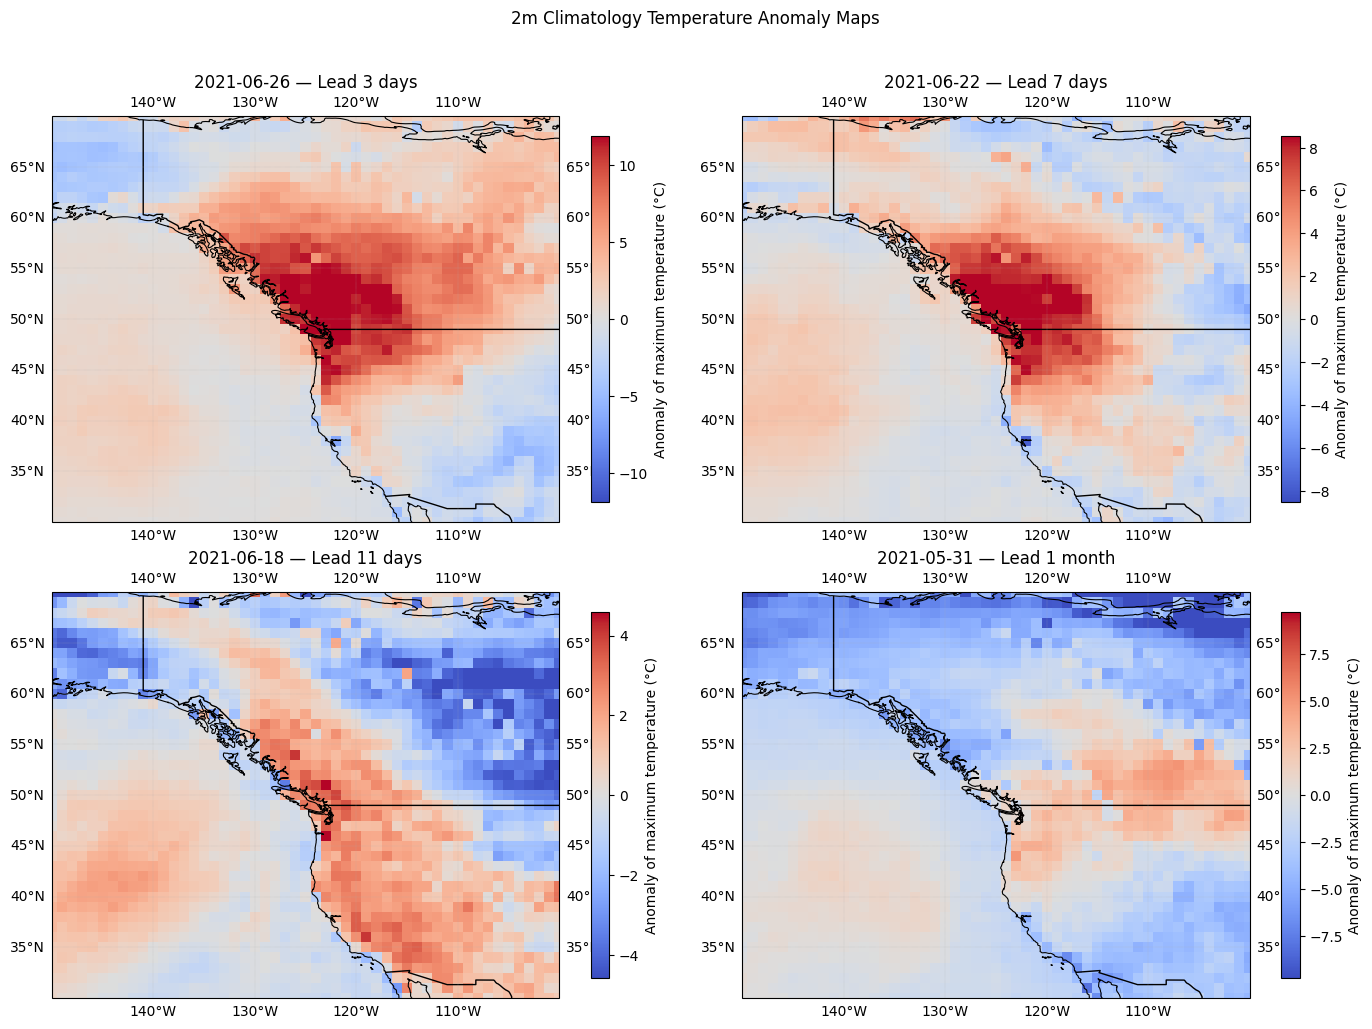

In [6]:
#Doing temp anomaly maps for different lead times
CLIM_FILE = "era5_june_climatology_1959_2020_2m_temperature.nc"

LAT1, LAT2 = 30, 70
LON1, LON2 = -150, -100

cases = [
    ("2021-06-26", "Lead 3 days"),
    ("2021-06-22", "Lead 7 days"),
    ("2021-06-18", "Lead 11 days"),
    ("2021-05-31", "Lead 1 month"),
]

def prep_2d_anomaly(pred_file):
    pred = xr.open_zarr(pred_file, consolidated=True, chunks="auto")
    clim = xr.open_dataset(CLIM_FILE, chunks="auto")

    pv = "2m_temperature" if "2m_temperature" in pred else "temperature"
    cv = "2m_temperature_june_max_climatology" if "2m_temperature_june_max_climatology" in clim else list(clim.data_vars)[0]

    if float(pred.lon.min()) < 0:
        pred = pred.assign_coords(lon=(pred.lon % 360)).sortby("lon")
    if float(clim.lon.min()) < 0:
        clim = clim.assign_coords(lon=(clim.lon % 360)).sortby("lon")

    lon1, lon2 = (LON1 % 360), (LON2 % 360)
    lat_slice = slice(LAT1, LAT2) if pred.lat[0] < pred.lat[-1] else slice(LAT2, LAT1)

    p = pred[pv]
    for d in ["ens", "ensemble", "member", "batch", "sample"]:
        if d in p.dims:
            p = p.mean(d)

    p = p.max("time")
    c = clim[cv].squeeze(drop=True)

    for d in list(p.dims):
        if d not in ("lat", "lon"):
            p = p.mean(d)
    for d in list(c.dims):
        if d not in ("lat", "lon"):
            c = c.isel({d: 0}, drop=True)

    p = p.sel(lat=lat_slice, lon=slice(lon1, lon2))
    c = c.sel(lat=lat_slice, lon=slice(lon1, lon2)).interp(lat=p.lat, lon=p.lon)

    a = (p - c).squeeze(drop=True)
    if a.ndim != 2:
        raise ValueError(f"Expected 2D field, got dims={a.dims}, shape={a.shape}")

    return a

fig, axes = plt.subplots(
    2, 2, figsize=(14, 10),
    subplot_kw={"projection": ccrs.PlateCarree()}
)
axes = axes.ravel()

for ax, (Date, title) in zip(axes, cases):
    Date2 = (pd.to_datetime(Date) - timedelta(days=1)).strftime("%Y-%m-%d")
    pred_file = f"predictions/init_{Date2}T00_30d_8ens_predictions.zarr"

    a = prep_2d_anomaly(pred_file)
    v = np.nanpercentile(np.abs(a), 98)

    m = ax.pcolormesh(
        a.lon.values, a.lat.values, a.values,
        shading="auto", cmap="coolwarm", vmin=-v, vmax=v,
        transform=ccrs.PlateCarree()
    )

    ax.set_extent([LON1, LON2, LAT1, LAT2], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
    ax.add_feature(cfeature.BORDERS, linewidth=1.0)
    ax.set_title(f"{Date} — {title}")
    ax.gridlines(draw_labels=True, linewidth=0.3, linestyle=":")

    fig.colorbar(m, ax=ax, label="Anomaly of maximum temperature (°C)", shrink=0.85)

fig.suptitle("2m Climatology Temperature Anomaly Maps", y=1.02)
fig.tight_layout()
plt.show()

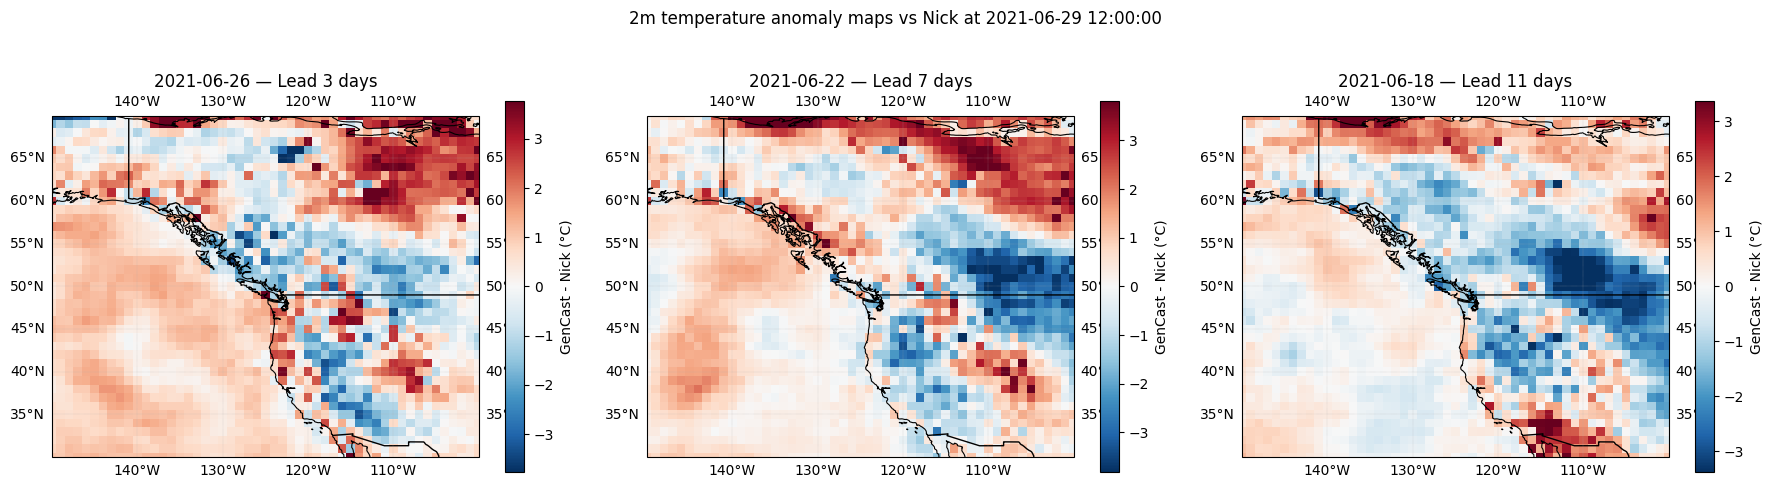

In [ ]:
# Nick vs GenCast anomaly maps
NICK_DIR = "/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf"
TARGET_TIME = pd.Timestamp("2021-06-29 12:00:00")

LAT1, LAT2 = 30, 70
LON1, LON2 = -150, -100

cases = [
    ("2021-06-26", 30, "Lead 3 days"),
    ("2021-06-22", 30, "Lead 7 days"),
    ("2021-06-18", 30, "Lead 11 days"),
]

def prep_anomaly(pred_file, nick_file, init_time, target_time):
    pred = fix_coords(standardize(xr.open_zarr(pred_file, consolidated=True, chunks="auto")))
    nick = fix_coords(standardize(xr.open_dataset(nick_file, engine="netcdf4", chunks="auto")))

    pv = "2m_temperature" if "2m_temperature" in pred else "temperature"
    nv = "t2m" if "t2m" in nick else list(nick.data_vars)[0]

    p = anchor_time(pred[pv], init_time)
    p = reduce_to_2d(to_celsius(p)).sel(time=target_time, method="nearest").load()

    n = reduce_to_2d(to_celsius(nick[nv])).sel(time=target_time, method="nearest").load()

    lon1, lon2 = sorted((LON1 % 360, LON2 % 360))
    lat1, lat2 = sorted((LAT1, LAT2))

    p = p.sel(latitude=slice(lat1, lat2), longitude=slice(lon1, lon2))
    n = n.sel(latitude=slice(lat1, lat2), longitude=slice(lon1, lon2))

    if p.sizes["latitude"] == 0 or p.sizes["longitude"] == 0:
        raise ValueError(f"Empty GenCast selection: {p.sizes}")
    if n.sizes["latitude"] == 0 or n.sizes["longitude"] == 0:
        raise ValueError(f"Empty Nick selection: {n.sizes}")

    if not (p.latitude.equals(n.latitude) and p.longitude.equals(n.longitude)):
        n = n.interp_like(p)

    a = (p - n).squeeze(drop=True)
    if a.ndim != 2:
        raise ValueError(f"Expected 2D field, got dims={a.dims}, shape={a.shape}")
    return a

fig, axes = plt.subplots(1, 3, figsize=(18, 5), subplot_kw={"projection": ccrs.PlateCarree()})
axes = axes.ravel()

for ax, (fcst_date, steps, title) in zip(axes, cases):
    file_date = (pd.to_datetime(fcst_date) - timedelta(days=1)).strftime("%Y-%m-%d")
    pred_file = f"predictions/init_{file_date}T00_{steps}d_8ens_predictions.zarr"
    nick_file = f"{NICK_DIR}/b2mg_{fcst_date}.nc"
    init_time = pd.to_datetime(file_date) + timedelta(hours=12)

    a = prep_anomaly(pred_file, nick_file, init_time, TARGET_TIME)
    v = np.nanpercentile(np.abs(a), 98)

    m = ax.pcolormesh(
        a.longitude, a.latitude, a,
        shading="auto", cmap="RdBu_r", vmin=-v, vmax=v,
        transform=ccrs.PlateCarree()
    )

    ax.set_extent([LON1, LON2, LAT1, LAT2], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
    ax.add_feature(cfeature.BORDERS, linewidth=1.0)
    ax.set_title(f"{fcst_date} — {title}")
    ax.gridlines(draw_labels=True, linewidth=0.3, linestyle=":")

    fig.colorbar(m, ax=ax, label="GenCast - Nick (°C)", shrink=0.85)

fig.suptitle(f"2m temperature anomaly maps vs Nick at {TARGET_TIME}", y=1.02)
fig.tight_layout()
plt.show()

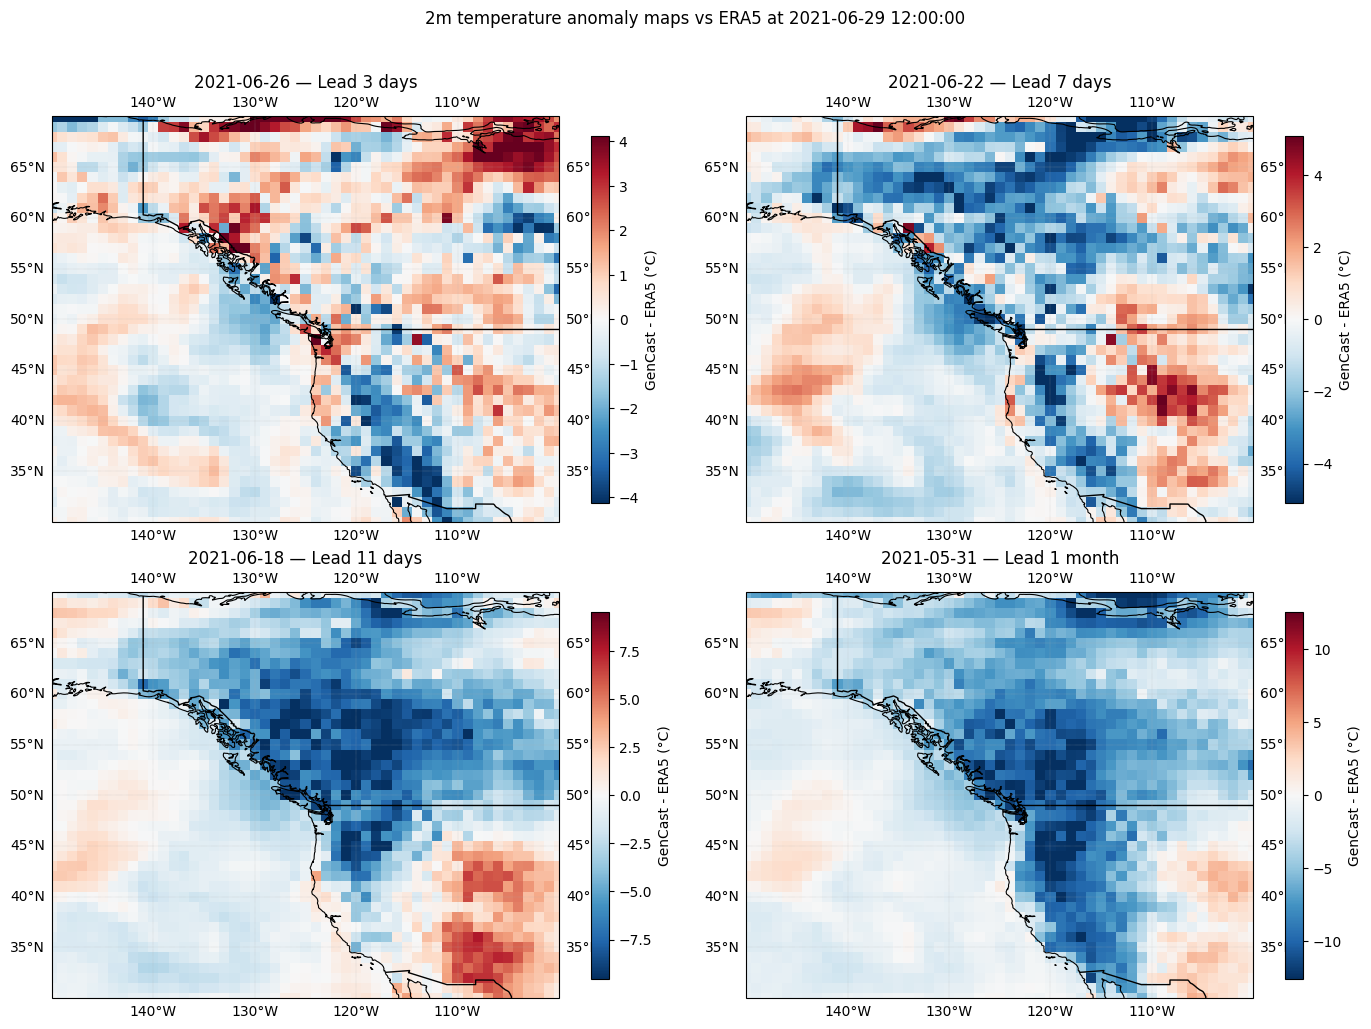

In [10]:
# Doing temp anomaly maps for different lead times vs ERA5
ERA5_FILE = "/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/era5/pnw025/sfc/2021.nc"
TARGET_TIME = pd.Timestamp("2021-06-29 12:00:00")

LAT1, LAT2 = 30, 70
LON1, LON2 = -150, -100

cases = [
    ("2021-06-26", 30, "Lead 3 days"),
    ("2021-06-22", 30, "Lead 7 days"),
    ("2021-06-18", 30, "Lead 11 days"),
    ("2021-05-31", 60, "Lead 1 month"),
]

def prep_anomaly(pred_file, era5_file, init_time, target_time):
    pred = fix_coords(standardize(xr.open_zarr(pred_file, consolidated=True, chunks="auto")))
    era5 = fix_coords(standardize(xr.open_dataset(era5_file, engine="netcdf4", chunks="auto")))

    pv = "2m_temperature" if "2m_temperature" in pred else "temperature"
    ev = "t2m" if "t2m" in era5 else list(era5.data_vars)[0]

    p = anchor_time(pred[pv], init_time)
    p = reduce_to_2d(to_celsius(p)).sel(time=target_time, method="nearest").load()
    e = reduce_to_2d(to_celsius(era5[ev])).sel(time=target_time, method="nearest").load()

    lon1, lon2 = sorted((LON1 % 360, LON2 % 360))
    lat1, lat2 = sorted((LAT1, LAT2))

    p = p.sel(latitude=slice(lat1, lat2), longitude=slice(lon1, lon2))
    e = e.sel(latitude=slice(lat1, lat2), longitude=slice(lon1, lon2))

    if p.sizes["latitude"] == 0 or p.sizes["longitude"] == 0:
        raise ValueError(f"Empty GenCast selection: {p.sizes}")
    if e.sizes["latitude"] == 0 or e.sizes["longitude"] == 0:
        raise ValueError(f"Empty ERA5 selection: {e.sizes}")

    if not (p.latitude.equals(e.latitude) and p.longitude.equals(e.longitude)):
        e = e.interp_like(p)

    a = (p - e).squeeze(drop=True)
    if a.ndim != 2:
        raise ValueError(f"Expected 2D field, got dims={a.dims}, shape={a.shape}")
    return a

fig, axes = plt.subplots(2, 2, figsize=(14, 10), subplot_kw={"projection": ccrs.PlateCarree()})
axes = axes.ravel()

for ax, (fcst_date, steps, title) in zip(axes, cases):
    file_date = (pd.to_datetime(fcst_date) - timedelta(days=1)).strftime("%Y-%m-%d")
    pred_file = f"predictions/init_{file_date}T00_{steps}d_8ens_predictions.zarr"
    init_time = pd.to_datetime(file_date) + timedelta(hours=12)

    a = prep_anomaly(pred_file, ERA5_FILE, init_time, TARGET_TIME)
    v = np.nanpercentile(np.abs(a), 98)

    m = ax.pcolormesh(
        a.longitude, a.latitude, a,
        shading="auto", cmap="RdBu_r", vmin=-v, vmax=v,
        transform=ccrs.PlateCarree()
    )

    ax.set_extent([LON1, LON2, LAT1, LAT2], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
    ax.add_feature(cfeature.BORDERS, linewidth=1.0)
    ax.set_title(f"{fcst_date} — {title}")
    ax.gridlines(draw_labels=True, linewidth=0.3, linestyle=":")

    fig.colorbar(m, ax=ax, label="GenCast - ERA5 (°C)", shrink=0.85)

fig.suptitle(f"2m temperature anomaly maps vs ERA5 at {TARGET_TIME}", y=1.02)
fig.tight_layout()
plt.show()

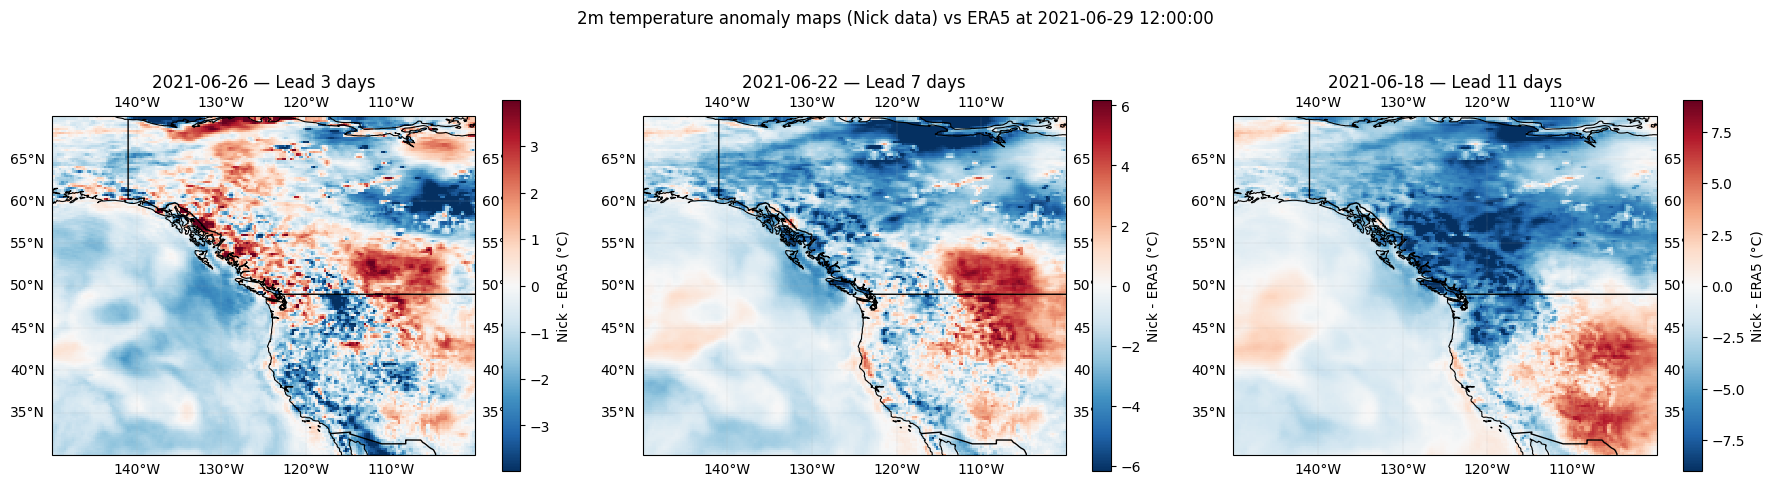

In [22]:
# Doing temp anomaly maps for different lead times vs ERA5
ERA5_FILE = "/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/era5/pnw025/sfc/2021.nc"
TARGET_TIME = pd.Timestamp("2021-06-29 12:00:00")

NICK_DIR = "/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf"

LAT1, LAT2 = 30, 70
LON1, LON2 = -150, -100

cases = [
    ("2021-06-26", "Lead 3 days"),
    ("2021-06-22", "Lead 7 days"),
    ("2021-06-18", "Lead 11 days"),
]

def prep_anomaly(nick_file, era5_file, target_time):
    nick = fix_coords(standardize(xr.open_dataset(nick_file, engine="netcdf4", chunks="auto")))
    era5 = fix_coords(standardize(xr.open_dataset(era5_file, engine="netcdf4", chunks="auto")))

    nv = "t2m" if "t2m" in nick else list(nick.data_vars)[0]
    ev = "t2m" if "t2m" in era5 else list(era5.data_vars)[0]

    n = reduce_to_2d(to_celsius(nick[nv])).sel(time=target_time, method="nearest").load()
    e = reduce_to_2d(to_celsius(era5[ev])).sel(time=target_time, method="nearest").load()

    lon1, lon2 = sorted((LON1 % 360, LON2 % 360))
    lat1, lat2 = sorted((LAT1, LAT2))

    n = n.sel(latitude=slice(lat1, lat2), longitude=slice(lon1, lon2))
    e = e.sel(latitude=slice(lat1, lat2), longitude=slice(lon1, lon2))

    if n.sizes["latitude"] == 0 or n.sizes["longitude"] == 0:
        raise ValueError(f"Empty Nick selection: {n.sizes}")
    if e.sizes["latitude"] == 0 or e.sizes["longitude"] == 0:
        raise ValueError(f"Empty ERA5 selection: {e.sizes}")

    if not (n.latitude.equals(e.latitude) and n.longitude.equals(e.longitude)):
        e = e.interp_like(n)

    a = (n - e).squeeze(drop=True)
    if a.ndim != 2:
        raise ValueError(f"Expected 2D field, got dims={a.dims}, shape={a.shape}")
    return a

fig, axes = plt.subplots(1, 3, figsize=(18, 5), subplot_kw={"projection": ccrs.PlateCarree()})
axes = axes.ravel()

for ax, (Date, title) in zip(axes, cases):
    nick_file = f"{NICK_DIR}/b2mg_{Date}.nc"

    a = prep_anomaly(nick_file, ERA5_FILE, TARGET_TIME)
    v = np.nanpercentile(np.abs(a), 98)

    m = ax.pcolormesh(
        a.longitude, a.latitude, a,
        shading="auto", cmap="RdBu_r", vmin=-v, vmax=v,
        transform=ccrs.PlateCarree()
    )

    ax.set_extent([LON1, LON2, LAT1, LAT2], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
    ax.add_feature(cfeature.BORDERS, linewidth=1.0)
    ax.set_title(f"{Date} — {title}")
    ax.gridlines(draw_labels=True, linewidth=0.3, linestyle=":")

    fig.colorbar(m, ax=ax, label="Nick - ERA5 (°C)", shrink=0.85)

fig.suptitle(f"2m temperature anomaly maps (Nick data) vs ERA5 at {TARGET_TIME}", y=1.02)
fig.tight_layout()
plt.show()